# 04d — Zero-shot LLM

## 1. Introduction and Objective

In the previous notebooks, I developed a regex baseline, two TF-IDF classifiers, and two Clinical BERT models to predict ICD-defined low back pain from ED chief complaints. These approaches represent different levels of model complexity and reliance on labeled training data.

In this notebook, I evaluate Qwen3.5:9b as a zero-shot classifier (M5) without task-specific fine-tuning or labeled examples. The objective is to examine whether a general-purpose large language model can achieve competitive classification performance using only a task description and the chief complaint text.

To reduce computational costs, I perform inference on unique chief complaints and cache the predictions locally. Predictions are then mapped back to the original encounters to preserve the evaluation population and class distribution.

The model is evaluated using the same ICD-derived reference labels and fixed validation partition established in Notebook 03. The test set remains held out until the final evaluation.

## 2. Development Dataset Preparation

I reuse the modeling dataset and fixed patient-level partitions established in Notebook 03. Unlike the supervised models developed in previous notebooks, M5 does not require labeled training data. The training partition is used only for prompt development and inference testing, while the validation partition is used for performance evaluation.

Since many ED encounters share identical chief complaints, I identify unique input texts to avoid redundant LLM inference. The original encounter-level dataset and reference labels remain unchanged. The test set remains held out until the final evaluation.

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np

SEED = 42

DATA_DIR = Path("../results/03_experimental_setup")
OUTPUT_DIR = Path("../results/04d_zero_shot_llm")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load the modeling dataset and fixed partitions
modeling_df = pd.read_csv(
    DATA_DIR / "modeling_dataset.csv",
    keep_default_na=False
)

splits_df = pd.read_csv(
    DATA_DIR / "dataset_splits.csv"
)

# Retain development partitions only
dev_splits = splits_df[
    splits_df["split"].isin(["train", "validation"])
]

dev_df = dev_splits.merge(
    modeling_df,
    on="stay_id",
    how="inner",
    validate="one_to_one"
)

train_df = dev_df[
    dev_df["split"] == "train"
].reset_index(drop=True)

val_df = dev_df[
    dev_df["split"] == "validation"
].reset_index(drop=True)

# Define model inputs and validation labels
X_train = train_df["chiefcomplaint_clean"]
X_val = val_df["chiefcomplaint_clean"]
y_val = val_df["lbp_label"]

print(f"Training encounters: {len(train_df):,}")
print(f"Validation encounters: {len(val_df):,}")

Training encounters: 295,877
Validation encounters: 42,268


In [6]:
# Verify partition coverage
assert len(dev_df) == len(dev_splits)

assert len(train_df) == 295877
assert len(val_df) == 42268

# Verify encounter-level and patient-level separation
assert dev_df["stay_id"].is_unique

assert set(train_df["subject_id"]).isdisjoint(
    set(val_df["subject_id"])
)

# Verify input text validity
assert X_train.notna().all()
assert X_val.notna().all()

assert X_train.str.strip().ne("").all()
assert X_val.str.strip().ne("").all()

# Verify binary reference labels
assert set(y_val.unique()) == {0, 1}

# Verify that the test partition is excluded
assert set(dev_df["split"].unique()) == {
    "train", "validation"
}

print("Development data validation: PASSED")

Development data validation: PASSED


In [7]:
# Identify exact unique input texts
unique_train_texts = X_train.drop_duplicates().reset_index(drop=True)
unique_val_texts = X_val.drop_duplicates().reset_index(drop=True)

# Summarize potential inference savings
text_inventory = (
    dev_df.groupby("split")["chiefcomplaint_clean"]
    .agg(
        encounters="size",
        unique_complaints="nunique"
    )
)

text_inventory["unique_pct"] = (
    text_inventory["unique_complaints"]
    / text_inventory["encounters"] * 100
)

text_inventory["potential_reduction_pct"] = (
    100 - text_inventory["unique_pct"]
)

text_inventory["redundant_calls"] = (
    text_inventory["encounters"]
    - text_inventory["unique_complaints"]
)

display(text_inventory.round(2))

,encounters,unique_complaints,unique_pct,potential_reduction_pct,redundant_calls
split,,,,,
train,295877,45725,15.45,84.55,250152
validation,42268,10771,25.48,74.52,31497


In [8]:
# Observed throughput from the synthetic benchmark
BENCHMARK_THROUGHPUT = 100 / 37.50

runtime_estimate = pd.DataFrame({
    "inference_strategy": [
        "Encounter-level inference",
        "Unique-text inference"
    ],
    "inference_calls": [
        len(X_val),
        len(unique_val_texts)
    ]
})

runtime_estimate["estimated_minutes"] = (
    runtime_estimate["inference_calls"]
    / BENCHMARK_THROUGHPUT / 60
)

runtime_estimate["estimated_hours"] = (
    runtime_estimate["estimated_minutes"] / 60
)

display(runtime_estimate.round(2))

,inference_strategy,inference_calls,estimated_minutes,estimated_hours
0,Encounter-level inference,42268,264.18,4.40
1,Unique-text inference,10771,67.32,1.12


The validation set contains 42,268 encounters but only 10,771 unique chief complaints. Performing inference once per unique input reduces the number of required LLM calls by 74.52% without changing the evaluation population.

Based on the preliminary synthetic benchmark, exact-text caching could reduce the estimated validation inference time from approximately 4.4 hours to 1.1 hours. Actual throughput will be assessed using the finalized prompt in the inference pilot.

## 3. LLM Configuration

I use Qwen3.5:9b through Ollama on a local Apple Silicon machine. The installed model uses NVFP4 quantization and runs through the MLX backend with GPU acceleration.

To support reproducible zero-shot classification, I disable thinking mode, set the temperature to zero, and fix the decoding seed. Since the task requires only a binary output, I limit the context window and maximum number of generated tokens.

I also record the model version, quantization, and inference configuration to ensure that cached predictions are associated with the same model and decoding settings.

In [9]:
import requests
import platform
import json
from importlib.metadata import version

API_BASE = "http://localhost:11434"
MODEL_NAME = "qwen3.5:9b"

# Retrieve Ollama version
version_response = requests.get(
    f"{API_BASE}/api/version",
    timeout=30
)
version_response.raise_for_status()

ollama_version = version_response.json()["version"]

# Retrieve installed model metadata
tags_response = requests.get(
    f"{API_BASE}/api/tags",
    timeout=30
)
tags_response.raise_for_status()

installed_models = tags_response.json()["models"]

model_metadata = next(
    model for model in installed_models
    if model["name"] == MODEL_NAME
)

# Record environment and model information
environment_config = {
    "platform": platform.platform(),
    "architecture": platform.machine(),
    "python_version": platform.python_version(),
    "requests_version": version("requests"),
    "ollama_version": ollama_version,
    "model_name": MODEL_NAME,
    "model_digest": model_metadata["digest"],
    "model_family": model_metadata["details"]["family"],
    "parameter_size": model_metadata["details"]["parameter_size"],
    "quantization": model_metadata["details"]["quantization_level"],
    "model_size_gb": model_metadata["size"] / 1e9
}

display(pd.Series(environment_config, name="Environment"))

platform                                 macOS-15.8.3-arm64-arm-64bit
architecture                                                    arm64
python_version                                                3.12.16
requests_version                                               2.34.2
ollama_version                                                0.40.18
model_name                                                 qwen3.5:9b
model_digest        d63f830f28d515fefea546f213fca7a75e9dd5176ef51a...
model_family                                                         
parameter_size                                                       
quantization                                                         
model_size_gb                                                7.639229
Name: Environment, dtype: object

In [10]:
# Fixed decoding configuration
OPTIONS = {
    "temperature": 0,
    "presence_penalty": 0,
    "repeat_penalty": 1,
    "num_predict": 8,
    "num_ctx": 2048,
    "seed": SEED
}

# Inference configuration
inference_config = {
    "model": MODEL_NAME,
    "stream": False,
    "think": False,
    "options": OPTIONS,
    "keep_alive": "30m"
}

display(pd.Series(OPTIONS, name="Decoding Configuration"))

print(f"Thinking mode: {inference_config['think']}")
print(f"Keep alive: {inference_config['keep_alive']}")
print(f"Inference endpoint: {API_BASE}/api/generate")

temperature            0
presence_penalty       0
repeat_penalty         1
num_predict            8
num_ctx             2048
seed                  42
Name: Decoding Configuration, dtype: int64

Thinking mode: False
Keep alive: 30m
Inference endpoint: http://localhost:11434/api/generate


In [11]:
# Verify the inference configuration using synthetic text
smoke_prompt = (
    "Does the following chief complaint indicate low back pain? "
    "Chief complaint: lower back pain. "
    "Respond with only 1 for yes or 0 for no."
)

smoke_response = requests.post(
    f"{API_BASE}/api/generate",
    json={
        **inference_config,
        "prompt": smoke_prompt
    },
    timeout=120
)

smoke_response.raise_for_status()
smoke_result = smoke_response.json()

assert smoke_result["response"].strip() in {"0", "1"}
assert smoke_result["done"]
assert not smoke_result.get("thinking")

# Retrieve loaded model information
ps_response = requests.get(
    f"{API_BASE}/api/ps",
    timeout=30
)

ps_response.raise_for_status()

loaded_model = next(
    model for model in ps_response.json()["models"]
    if model["name"] == MODEL_NAME
)

# Summarize runtime information
runtime_info = {
    "response": smoke_result["response"].strip(),
    "generated_tokens": smoke_result["eval_count"],
    "context_length": loaded_model.get("context_length"),
    "loaded_size_gb": loaded_model["size"] / 1e9,
    "gpu_size_gb": loaded_model["size_vram"] / 1e9,
    "total_seconds": smoke_result["total_duration"] / 1e9
}

display(pd.Series(runtime_info, name="Runtime"))

print("LLM configuration validation: PASSED")

response                   1
generated_tokens           1
context_length          2048
loaded_size_gb      7.734938
gpu_size_gb         7.734938
total_seconds       0.647982
Name: Runtime, dtype: object

LLM configuration validation: PASSED


## 4. Zero-shot Prompt Design

### 4.1 Task Definition

The zero-shot classification task is to predict whether an ED encounter is likely to receive a low back pain diagnosis code based solely on its chief complaint. The objective is not to establish a clinical diagnosis or assign a specific ICD code.

### 4.2 Prompt Design

I use a fixed task-oriented prompt that describes the binary classification objective, provides the chief complaint, and requires a single binary output. No labeled examples, ICD code lists, or researcher-defined keyword rules are included in the prompt.

This design allows the model to rely on its pretrained knowledge without task-specific fine-tuning or few-shot demonstrations. The prompt remains fixed during validation and final test evaluation.

In [12]:
PROMPT_VERSION = "v1"

PROMPT_TEMPLATE = """Predict whether an emergency department encounter is likely to receive a diagnosis code for low back pain based only on the chief complaint.

Chief complaint:
{chief_complaint}

Respond with only one digit:
1 = Likely to receive a low back pain diagnosis code.
0 = Not likely to receive a low back pain diagnosis code.

Output:"""


def build_prompt(text):
    return PROMPT_TEMPLATE.format(
        chief_complaint=text
    )


# Inspect the prompt using synthetic text
print(build_prompt("lower back pain"))

Predict whether an emergency department encounter is likely to receive a diagnosis code for low back pain based only on the chief complaint.

Chief complaint:
lower back pain

Respond with only one digit:
1 = Likely to receive a low back pain diagnosis code.
0 = Not likely to receive a low back pain diagnosis code.

Output:


### 4.3 Prompt Validation

Before applying the prompt to the development dataset, I test it using synthetic chief complaints to verify that the model follows the task instructions and returns the required binary output format. These inputs are used only for functional testing and are not included as examples in the classification prompt.

In [13]:
synthetic_texts = [
    "lower back pain",
    "chest pain",
    "lbp",
    "headache",
    "backache",
    "abdominal pain",
    "sciatica",
    "ankle injury",
    "lumbar pain",
    "shortness of breath"
]

prompt_test_records = []

for text in synthetic_texts:

    response = requests.post(
        f"{API_BASE}/api/generate",
        json={
            **inference_config,
            "prompt": build_prompt(text)
        },
        timeout=120
    )

    response.raise_for_status()
    result = response.json()

    prediction = result["response"].strip()

    prompt_test_records.append({
        "chief_complaint": text,
        "response": prediction,
        "valid_output": prediction in {"0", "1"},
        "generated_tokens": result.get("eval_count"),
        "inference_seconds": result["total_duration"] / 1e9
    })

prompt_test_df = pd.DataFrame(prompt_test_records)

display(prompt_test_df.round(4))

assert prompt_test_df["valid_output"].all()

print("Prompt validation: PASSED")

,chief_complaint,response,valid_output,generated_tokens,inference_seconds
0,lower back pain,1,True,1,0.9388
1,chest pain,0,True,1,0.7153
2,lbp,1,True,1,0.5317
3,headache,0,True,1,0.5284
4,backache,1,True,1,0.5568
5,abdominal pain,0,True,1,0.5871
6,sciatica,1,True,1,0.5333
7,ankle injury,0,True,1,0.5477
8,lumbar pain,1,True,1,0.5958
9,shortness of breath,0,True,1,0.6817


Prompt validation: PASSED


In [14]:
prompt_config = {
    "prompt_version": PROMPT_VERSION,
    "prompt_template": PROMPT_TEMPLATE,
    "input_column": "chiefcomplaint_clean",
    "learning_approach": "zero_shot",
    "labeled_examples": 0,
    "valid_outputs": ["0", "1"]
}

with open(OUTPUT_DIR / "m5_prompt_config.json", "w") as f:
    json.dump(prompt_config, f, indent=4)

print("Prompt configuration saved.")

Prompt configuration saved.


## 5. Inference Pipeline and Caching

### 5.1 Cache Configuration

To avoid redundant LLM inference and support interrupted execution, I use a persistent SQLite cache to store predictions for unique chief complaints.

Each cached prediction is associated with a configuration identifier derived from the model digest, prompt template, inference settings, and Ollama version. This prevents predictions generated under different configurations from being reused incorrectly.

Caching reduces computational costs without changing the original encounter-level evaluation dataset.

In [15]:
import hashlib
import sqlite3

# Define the configuration associated with cached predictions
cache_config = {
    "model_name": MODEL_NAME,
    "model_digest": environment_config["model_digest"],
    "ollama_version": environment_config["ollama_version"],
    "prompt_version": PROMPT_VERSION,
    "prompt_template": PROMPT_TEMPLATE,
    "inference_config": inference_config,
    "backend": "mlx"
}

# Generate a stable configuration identifier
config_string = json.dumps(
    cache_config,
    sort_keys=True,
    ensure_ascii=False
)

CONFIG_ID = hashlib.sha256(
    config_string.encode("utf-8")
).hexdigest()

print(f"Configuration ID: {CONFIG_ID}")

Configuration ID: cea23de3f4340b041f8a9fb611ccdb4d3b2296cbdc133ac71e1854714bbe91aa


In [16]:
CACHE_PATH = OUTPUT_DIR / "m5_prediction_cache.sqlite"

# Initialize the persistent prediction cache
with sqlite3.connect(CACHE_PATH) as conn:

    conn.execute("""
        CREATE TABLE IF NOT EXISTS predictions (
            config_id TEXT NOT NULL,
            chief_complaint TEXT NOT NULL,
            prediction INTEGER NOT NULL
                CHECK (prediction IN (0, 1)),
            inference_seconds REAL NOT NULL,
            generated_tokens INTEGER,
            created_at TEXT DEFAULT CURRENT_TIMESTAMP,
            PRIMARY KEY (config_id, chief_complaint)
        )
    """)

    conn.commit()

print(f"Cache file: {CACHE_PATH.name}")
print(f"Cache initialized: {CACHE_PATH.exists()}")

Cache file: m5_prediction_cache.sqlite
Cache initialized: True


In [17]:
# Check previously completed predictions
with sqlite3.connect(CACHE_PATH) as conn:

    cached_count = conn.execute("""
        SELECT COUNT(*)
        FROM predictions
        WHERE config_id = ?
    """, (CONFIG_ID,)).fetchone()[0]

print(f"Cached predictions: {cached_count:,}")
print("Cache configuration validation: PASSED")

Cached predictions: 0
Cache configuration validation: PASSED


### 5.2 Inference Function

I define a reusable inference function that sends each chief complaint to the local Ollama API using the fixed prompt and decoding configuration. The function accepts only valid binary outputs and records inference time and generated token counts.

A limited retry mechanism handles temporary request failures and invalid responses without modifying the prompt or decoding parameters. Persistent failures are explicitly reported rather than automatically assigned a negative label.

In [18]:
import time

MAX_ATTEMPTS = 3
REQUEST_TIMEOUT = 120
RETRY_DELAY = 1


def predict_lbp(text):

    prompt = build_prompt(text)

    for attempt in range(1, MAX_ATTEMPTS + 1):

        try:
            response = requests.post(
                f"{API_BASE}/api/generate",
                json={
                    **inference_config,
                    "prompt": prompt
                },
                timeout=REQUEST_TIMEOUT
            )

            response.raise_for_status()
            result = response.json()

            # Validate the completed response
            if not result.get("done", False):
                raise ValueError("Incomplete response")

            if result.get("thinking"):
                raise ValueError("Unexpected thinking output")

            # Accept only exact binary outputs
            prediction = result["response"].strip()

            if prediction not in {"0", "1"}:
                raise ValueError("Invalid binary output")

            return {
                "prediction": int(prediction),
                "inference_seconds": result["total_duration"] / 1e9,
                "generated_tokens": result["eval_count"],
                "attempts": attempt
            }

        except (requests.RequestException, ValueError, KeyError) as error:

            if attempt == MAX_ATTEMPTS:
                raise RuntimeError(
                    f"Inference failed after {MAX_ATTEMPTS} attempts. "
                    f"Error type: {type(error).__name__}"
                ) from None

            time.sleep(RETRY_DELAY)

In [19]:
inference_test_texts = [
    "lower back pain",
    "chest pain",
    "sciatica",
    "lbp",
    "headache"
]

inference_test_records = []

for text in inference_test_texts:

    result = predict_lbp(text)

    inference_test_records.append({
        "chief_complaint": text,
        **result
    })

inference_test_df = pd.DataFrame(
    inference_test_records
)

display(inference_test_df.round(4))

# Verify binary predictions and inference metadata
assert inference_test_df["prediction"].isin([0, 1]).all()
assert (inference_test_df["inference_seconds"] > 0).all()
assert inference_test_df["attempts"].between(
    1, MAX_ATTEMPTS
).all()

print("Inference function validation: PASSED")

,chief_complaint,prediction,inference_seconds,generated_tokens,attempts
0,lower back pain,1,0.7484,1,1
1,chest pain,0,0.7356,1,1
2,sciatica,1,0.5293,1,1
3,lbp,1,0.5627,1,1
4,headache,0,0.5626,1,1


Inference function validation: PASSED


### 5.3 Cached Inference Pipeline

I integrate the inference function with the persistent prediction cache. Before processing a collection of chief complaints, the pipeline retrieves existing predictions associated with the current configuration and identifies the texts that still require inference.

Each newly generated prediction is saved immediately to the SQLite database. If execution is interrupted, subsequent runs reuse the completed predictions and process only the remaining texts. This avoids redundant computation while preserving the original encounter-level evaluation dataset.

In [20]:
def load_cached_predictions():

    with sqlite3.connect(CACHE_PATH) as conn:

        records = conn.execute("""
            SELECT chief_complaint, prediction
            FROM predictions
            WHERE config_id = ?
        """, (CONFIG_ID,)).fetchall()

    return dict(records)

In [21]:
from tqdm.auto import tqdm
from contextlib import closing


def run_cached_inference(texts):

    # Preserve exact input text and remove duplicates
    unique_texts = list(dict.fromkeys(texts))

    # Load existing predictions
    cached_predictions = load_cached_predictions()

    # Identify texts that still require inference
    pending_texts = [
        text for text in unique_texts
        if text not in cached_predictions
    ]

    cache_hits = len(unique_texts) - len(pending_texts)

    print(f"Unique input texts: {len(unique_texts):,}")
    print(f"Cache hits: {cache_hits:,}")
    print(f"Inference required: {len(pending_texts):,}")

    start = time.perf_counter()

    # Process and persist new predictions
    with closing(sqlite3.connect(CACHE_PATH)) as conn:

        for text in tqdm(
            pending_texts,
            desc="LLM inference"
        ):

            result = predict_lbp(text)

            conn.execute("""
                INSERT INTO predictions (
                    config_id,
                    chief_complaint,
                    prediction,
                    inference_seconds,
                    generated_tokens
                )
                VALUES (?, ?, ?, ?, ?)
            """, (
                CONFIG_ID,
                text,
                result["prediction"],
                result["inference_seconds"],
                result["generated_tokens"]
            ))

            # Persist each completed prediction immediately
            conn.commit()

            cached_predictions[text] = result["prediction"]

    elapsed = time.perf_counter() - start

    # Return predictions in the requested input order
    predictions = {
        text: cached_predictions[text]
        for text in unique_texts
    }

    assert len(predictions) == len(unique_texts)
    assert set(predictions.values()).issubset({0, 1})

    print(f"\nCompleted unique predictions: {len(predictions):,}")
    print(f"New inference calls: {len(pending_texts):,}")
    print(f"Elapsed time: {elapsed:.2f} seconds")

    if pending_texts:
        print(
            f"Throughput: "
            f"{len(pending_texts) / elapsed:.2f} texts/sec"
        )

    return predictions

In [22]:
def map_predictions_to_encounters(texts, predictions):

    mapped_predictions = texts.map(predictions)

    # Verify complete prediction coverage
    assert mapped_predictions.notna().all()
    assert mapped_predictions.isin([0, 1]).all()
    assert len(mapped_predictions) == len(texts)

    return mapped_predictions.astype(int)

## 6. Validation Inference

Using the finalized prompt and inference configuration, I apply the cached inference pipeline to the validation set. Each unique chief complaint is processed only once, and the resulting prediction is stored locally for subsequent reuse.

The predictions are mapped back to the original validation encounters to preserve the evaluation population and class distribution. I verify complete prediction coverage before proceeding to performance evaluation.

In [23]:
# Run inference on unique validation chief complaints
val_prediction_dict = run_cached_inference(unique_val_texts)

Unique input texts: 10,771
Cache hits: 0
Inference required: 10,771


LLM inference:   0%|          | 0/10771 [00:00<?, ?it/s]


Completed unique predictions: 10,771
New inference calls: 10,771
Elapsed time: 10093.74 seconds
Throughput: 1.07 texts/sec


In [24]:
# Map unique-text predictions back to encounters
m5_val_pred = map_predictions_to_encounters(
    X_val,
    val_prediction_dict
)

# Verify prediction coverage and alignment
assert len(m5_val_pred) == len(y_val)
assert m5_val_pred.index.equals(y_val.index)
assert m5_val_pred.isin([0, 1]).all()

prediction_summary = pd.DataFrame({
    "metric": [
        "Validation encounters",
        "Unique chief complaints",
        "Completed unique predictions",
        "Mapped encounter predictions",
        "Missing predictions"
    ],
    "count": [
        len(X_val),
        len(unique_val_texts),
        len(val_prediction_dict),
        len(m5_val_pred),
        m5_val_pred.isna().sum()
    ]
})

display(prediction_summary)

print("Validation inference: COMPLETED")

,metric,count
0,Validation encounters,42268
1,Unique chief complaints,10771
2,Completed unique predictions,10771
3,Mapped encounter predictions,42268
4,Missing predictions,0


Validation inference: COMPLETED


The local LLM completed inference on all 10,771 unique validation chief complaints in approximately 2.8 hours, with an average throughput of 1.07 texts per second. The observed throughput was lower than that of the preliminary synthetic benchmark.

Exact-text caching avoided 31,497 redundant inference calls, reducing the required number of requests by 74.52%. All predictions were successfully mapped back to the 42,268 validation encounters, with no missing predictions.

## 7. Validation Performance

### 7.1 M5 Performance Evaluation

I evaluate M5 using the same validation partition and ICD-derived reference labels used for M0–M4. Performance is measured using positive-class precision, recall, F1 score, and the confusion matrix.

Similar to the regex baseline, M5 produces binary predictions rather than continuous probability scores. Therefore, AUROC and average precision are not reported.

In [25]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_val,
    m5_val_pred,
    labels=[0, 1]
).ravel()

# Calculate positive-class classification metrics
m5_metrics = {
    "precision": precision_score(
        y_val, m5_val_pred, zero_division=0
    ),
    "recall": recall_score(
        y_val, m5_val_pred, zero_division=0
    ),
    "f1": f1_score(
        y_val, m5_val_pred, zero_division=0
    ),
    "auroc": np.nan,
    "average_precision": np.nan,
    "tn": tn,
    "fp": fp,
    "fn": fn,
    "tp": tp
}

m5_validation_metrics = pd.DataFrame(
    [m5_metrics],
    index=pd.Index(["M5"], name="model")
)

display(m5_validation_metrics.round(4))

,precision,recall,f1,auroc,average_precision,tn,fp,fn,tp
model,,,,,,,,,
M5,0.5195,0.7022,0.5972,NaN,NaN,39576,1060,486,1146


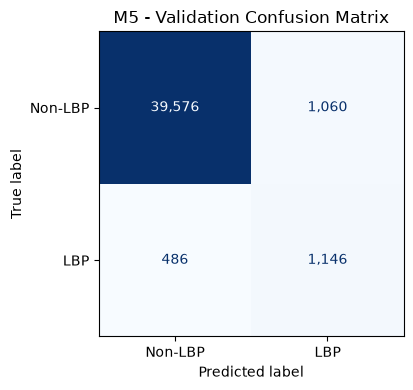

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    m5_val_pred,
    labels=[0, 1],
    display_labels=["Non-LBP", "LBP"],
    cmap="Blues",
    values_format=",d",
    colorbar=False,
    ax=ax
)

ax.set_title("M5 - Validation Confusion Matrix")

plt.tight_layout()
plt.show()

### 7.2 Comparison with Previous Models

I combine the validation results from M0–M5 to compare rule-based, traditional machine learning, Clinical BERT, and zero-shot LLM approaches under the same evaluation conditions. The comparison focuses on positive-class precision, recall, and F1 score, which are available for all six models.

In [27]:
# Load validation results from M0–M4
previous_metrics = pd.read_csv(
    "../results/04c_clinical_bert_models/combined_validation_metrics.csv",
    index_col="model"
)

# Combine all six models
all_validation_metrics = pd.concat([
    previous_metrics,
    m5_validation_metrics
])

# Verify model coverage
assert all_validation_metrics.index.is_unique
assert set(all_validation_metrics.index) == {
    "M0", "M1", "M2", "M3", "M4", "M5"
}

all_validation_metrics = all_validation_metrics.loc[
    ["M0", "M1", "M2", "M3", "M4", "M5"]
]

# Verify evaluation population
assert (
    all_validation_metrics[["tn", "fp", "fn", "tp"]]
    .sum(axis=1) == len(y_val)
).all()

display(all_validation_metrics.round(4))

,precision,recall,f1,auroc,average_precision,tn,fp,fn,tp
model,,,,,,,,,
M0,0.6686,0.6924,0.6803,NaN,NaN,40076,560,502,1130
M1,0.7145,0.6746,0.6940,0.9481,0.6591,40196,440,531,1101
M2,0.7079,0.6844,0.6960,0.9476,0.6653,40175,461,515,1117
M3,0.7069,0.6752,0.6907,0.9451,0.6675,40179,457,530,1102
M4,0.6942,0.7010,0.6976,0.9382,0.6827,40132,504,488,1144
M5,0.5195,0.7022,0.5972,NaN,NaN,39576,1060,486,1146


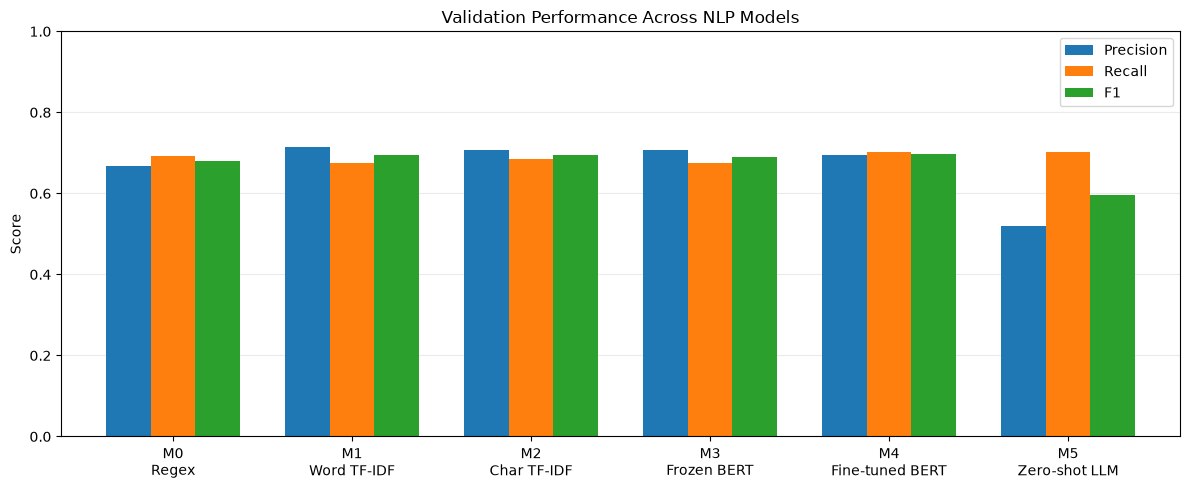

In [28]:
model_names = [
    "M0\nRegex",
    "M1\nWord TF-IDF",
    "M2\nChar TF-IDF",
    "M3\nFrozen BERT",
    "M4\nFine-tuned BERT",
    "M5\nZero-shot LLM"
]

fig, ax = plt.subplots(figsize=(12, 5))

all_validation_metrics[
    ["precision", "recall", "f1"]
].plot(
    kind="bar",
    ax=ax,
    width=0.75
)

ax.set_title("Validation Performance Across NLP Models")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.set_xticklabels(model_names, rotation=0)
ax.legend(["Precision", "Recall", "F1"])

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 7.3 Observations

The zero-shot LLM achieves the highest recall (0.7022) among the six models but substantially lower precision (0.5195), resulting in the lowest F1 score (0.5972). Compared with fine-tuned Clinical BERT, it identifies only two additional reference-positive encounters while producing 556 additional false positives.

One possible explanation is that the LLM's pretrained understanding of low back pain does not fully align with the ICD-derived reference definition used in this study. Unlike the supervised models, the zero-shot LLM has no opportunity to learn the relationship between chief complaint expressions and the specific reference labels.

Interestingly, both TF-IDF models and the simple regex baseline outperform the zero-shot LLM in terms of F1 score. These preliminary results suggest that greater model complexity and general language understanding do not necessarily translate into better performance on this short-text classification task. Final conclusions will be based on the held-out test set.

## 8. Save Results

I save the finalized model configuration, prompt, validation metrics, and combined model comparison results for subsequent evaluation. The persistent prediction cache is retained to avoid repeating inference on identical chief complaints during the final test evaluation.

All generated artifacts are stored locally in the results directory. The model, prompt, and inference configuration remain fixed for the held-out test evaluation.

In [29]:
m5_config = {
    "model_id": "M5",
    "learning_approach": "zero_shot",
    "input_column": "chiefcomplaint_clean",
    "environment": environment_config,
    "inference_config": inference_config,
    "prompt_config": prompt_config,
    "cache_config": cache_config,
    "config_id": CONFIG_ID,
    "cache_path": CACHE_PATH.name,
    "validation_f1": float(
        m5_validation_metrics.loc["M5", "f1"]
    )
}

with open(OUTPUT_DIR / "m5_config.json", "w") as f:
    json.dump(m5_config, f, indent=4)

print("M5 configuration saved.")

M5 configuration saved.


In [30]:
# Save individual model results
m5_validation_metrics.to_csv(
    OUTPUT_DIR / "validation_metrics.csv"
)

# Save combined results for M0–M5
all_validation_metrics.to_csv(
    OUTPUT_DIR / "combined_validation_metrics.csv"
)

print("Validation results saved.")

Validation results saved.


In [31]:
validation_inference_summary = {
    "validation_encounters": len(X_val),
    "unique_complaints": len(unique_val_texts),
    "completed_unique_predictions": len(val_prediction_dict),
    "mapped_predictions": len(m5_val_pred),
    "missing_predictions": int(m5_val_pred.isna().sum()),
    "cache_hits_at_start": 0,
    "new_inference_calls": 10771,
    "elapsed_seconds": 10093.74
}

validation_inference_summary["avoided_inference_calls"] = (
    len(X_val) - len(unique_val_texts)
)

validation_inference_summary["inference_reduction_pct"] = (
    1 - len(unique_val_texts) / len(X_val)
) * 100

validation_inference_summary["throughput_texts_per_second"] = (
    validation_inference_summary["new_inference_calls"]
    / validation_inference_summary["elapsed_seconds"]
)

with open(OUTPUT_DIR / "m5_inference_summary.json", "w") as f:
    json.dump(validation_inference_summary, f, indent=4)

print("Inference summary saved.")

Inference summary saved.


In [32]:
output_inventory = pd.DataFrame([
    {
        "file": path.name,
        "size_kb": path.stat().st_size / 1024
    }
    for path in sorted(OUTPUT_DIR.iterdir())
    if path.is_file()
])

display(output_inventory.round(2))

,file,size_kb
0,combined_validation_metrics.csv,0.67
1,m5_config.json,2.69
2,m5_inference_summary.json,0.41
3,m5_prediction_cache.sqlite,2508.00
4,m5_prompt_config.json,0.54
5,validation_metrics.csv,0.14
